# Frozen checkpoint: errors, novelty, boundaries

4000 checkpoint texts; same saved 12k-fit pilot. No retraining, calibration or final audit scoring. Counts from the full checkpoint and the 200-case diagnostic review are kept separate. Contextual notes are AI-assisted hypotheses, not corrected ground truth.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd() if (Path.cwd() / 'reports/checkpoint_error_analysis.json').exists() else Path.cwd() / 'assignment3'
BASE = BASE.resolve()
result = json.loads((BASE / 'reports/checkpoint_error_analysis.json').read_text(encoding='utf-8'))
display(pd.read_csv(BASE / 'reports/checkpoint_novelty_metrics.csv'))
display(pd.read_csv(BASE / 'reports/checkpoint_gold_OOV_recall.csv'))

,slice,tp,fp,fn,precision,recall,f1,recall_95ci,f1_95ci,raw_gold_mentions,strict_exact_mention_recall
0,seen,756,182,125,0.80597,0.858116,0.831226,"[0.8344557873090481, 0.8811208182184602]","[0.8128957973517559, 0.8493615100551124]",889,0.852643
1,unseen,131,735,306,0.15127,0.299771,0.201074,"[0.2506015862996405, 0.3478320922411722]","[0.1676822169100184, 0.2334839049952361]",439,0.291572


,gold_slice,gold,tp,recall
0,all_tokens_in_vocab,947,763,0.805702
1,contains_UNK,371,124,0.334232


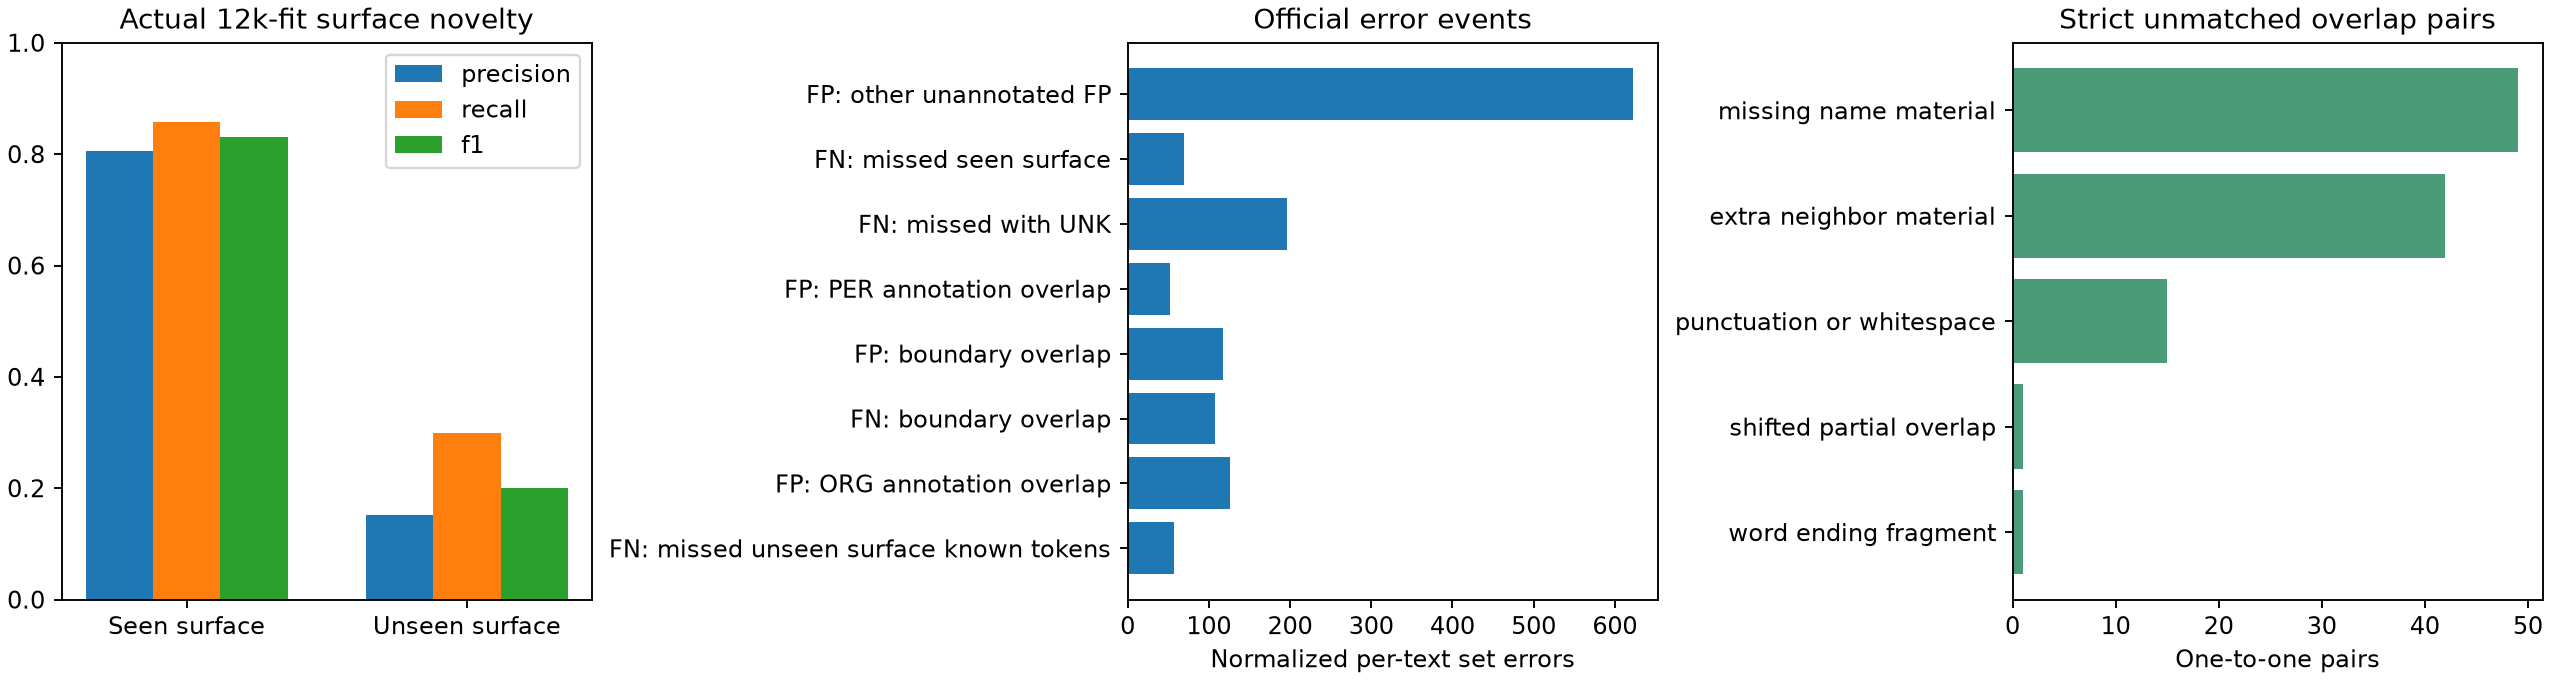

In [2]:
display(Image(filename=str(BASE / 'figures/checkpoint_error_analysis.png')))

In [3]:
display(pd.DataFrame(result['official_error_categories']))
display(pd.Series(result['overlap_pair_relations']))

,kind,category,count
0,FP,other_unannotated_FP,622
1,FN,missed_seen_surface,70
2,FN,missed_with_UNK,196
3,FP,PER_annotation_overlap,52
4,FP,boundary_overlap,117
5,FN,boundary_overlap,108
6,FP,ORG_annotation_overlap,126
7,FN,missed_unseen_surface_known_tokens,57


missing_name_material        49
extra_neighbor_material      42
punctuation_or_whitespace    15
shifted_partial_overlap       1
word_ending_fragment          1
dtype: int64

In [4]:
review = pd.read_csv(BASE / 'reports/checkpoint_review_200_annotated.csv')
assert len(review) == 200 and review.row_id.nunique() == 200
display(review[['case_id', 'kind', 'surface', 'seen_in_pilot', 'contains_UNK', 'context_review_tag', 'context_review_note']].head(20))
print('Full 200-case contextual notes are in reports/CHECKPOINT_REVIEW_200.md')

Full 200-case contextual notes are in reports/CHECKPOINT_REVIEW_200.md


,case_id,kind,surface,seen_in_pilot,contains_UNK,context_review_tag,context_review_note
0,1,FN,Покровському районі,False,True,missing_name_material,Граница «Покровському районі» не совпала с «По...
1,2,FN,Прем`єр Палас,False,True,multiword_name,Название гостиницы потеряло первый компонент и...
2,3,FN,Слов'янська Донецької області,False,True,granularity_policy,Gold объединяет город и область в одну сущност...
3,4,FN,вулиці С. Ковпака,False,True,address_boundary,Разорвано название улицы с инициалом; «вулиці»...
4,5,FN,Челябінська область,False,True,entity_type_context,В этом же тексте «Дніпро» — название программы...
5,6,FN,Чорнобильської зони,False,False,missing_name_material,Граница «Чорнобильської зони» не совпала с «зо...
6,7,FN,Повітрофлотського шляхопроводу,False,True,split_location,Одно название путепровода разбито на две предс...
7,8,FN,"Москви, у тому чи",False,False,possible_annotation_error,"Gold «Москви, у тому чи» захватывает обрывок с..."
8,9,FN,Франківська область,False,False,granularity_policy,Gold разделяет «Івано-Франківська» на части; м...
9,10,FN,Антарктиді,False,True,extra_neighbor_material,Граница «Антарктиді» не совпала с «Антарктиді ...


## Interpretation

New surface is defined relative to LOC labels in the actual 12k pilot fit, not the whole million-row corpus. OOV is different. Boundary overlaps are diagnostic, not proof that a decoder fix would resolve every error. See the full report for label-policy ambiguities and safeguards.